# LifeGuard-RL XJTU SOH validation

This follow-up tests how much earlier in charging SOH can be estimated, and whether models trained at one charging rate work at the other rate. It checks the large error at cycle 390 of `XJTU_2C_battery-2` against neighboring raw traces.

1. Attach the Kaggle dataset containing **XJTU.zip** and **XJTU_labels.json**. Extracted XJTU pickle files also work. Set **INPUT_ROOT** if more than one XJTU input is attached.
2. Run all cells for the CPU comparison. To add the CNN, select a **single GPU** in Kaggle and set **RUN_CNN = True** in the configuration.
3. Download **lifeguard_soh_validation_results.zip** from the notebook output. It contains the comparison, held-out predictions, split assignments, and the cycle 390 diagnostic plot.

[BatteryLife v12](https://zenodo.org/records/21149533) · [Original XJTU study](https://pmc.ncbi.nlm.nih.gov/articles/PMC11109204/)

In [35]:
RUN_CNN = False
INPUT_ROOT = None
OUTPUT_ROOT = None
SEED = 42

from collections import Counter
from contextlib import nullcontext
from importlib.metadata import version
import json
from pathlib import Path, PurePosixPath
import pickle
from tempfile import TemporaryDirectory
from time import perf_counter
import traceback
from zipfile import ZIP_DEFLATED, ZipFile

from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, ParameterGrid, StratifiedKFold
from threadpoolctl import threadpool_limits

if INPUT_ROOT is None:
    if Path("/kaggle/input").is_dir():
        INPUT_ROOT = "/kaggle/input"
    elif Path.cwd().name == "notebooks":
        INPUT_ROOT = Path.cwd().parent
    else:
        INPUT_ROOT = Path.cwd()
if OUTPUT_ROOT is None:
    OUTPUT_ROOT = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd() / "outputs"
INPUT_ROOT = Path(INPUT_ROOT).resolve()
OUTPUT_ROOT = Path(OUTPUT_ROOT).resolve()
if not INPUT_ROOT.is_dir():
    raise FileNotFoundError(f"Input folder does not exist: {INPUT_ROOT}")

## SOH target and observation windows

SOH is measured as 100 times the full discharge capacity divided by the 2.0 Ah nominal capacity. Charging features come from either the first upward crossing of **4.1 V** or the first charging-taper sample with current at or below **0.2 A** and voltage at or above **4.15 V**. The early pipeline can extract its features even when the taper is absent.

The primary comparisons use cycles where both windows and the SOH target are available. The quality table gives the coverage of each window on the full set of recorded cycles.

In [36]:
PILOT_EOLS = {
    "XJTU_2C_battery-7": 401,
    "XJTU_3C_battery-2": 291,
}
FIXED_CELLS = {
    f"XJTU_{rate}C_battery-{number}": rate
    for rate, count in ((2, 8), (3, 15))
    for number in range(1, count + 1)
}
POINTS = 256
def unique_path(paths, description):
    paths = sorted(set(paths))
    if len(paths) != 1:
        detail = ", ".join(str(path) for path in paths) or "none found"
        raise ValueError(f"Expected one {description}, found {detail}. Set INPUT_ROOT to your dataset directory.")
    return paths[0]


def locate_data(root, cell_ids):
    archives = list(root.rglob("XJTU.zip"))
    if archives:
        archive_path = unique_path(archives, "XJTU.zip")
        with ZipFile(archive_path) as archive:
            members = {}
            for info in archive.infolist():
                name = PurePosixPath(info.filename).stem
                if info.filename.endswith(".pkl") and name in cell_ids:
                    if name in members:
                        raise ValueError(f"Duplicate cell {name} in {archive_path}")
                    members[name] = info
        if missing := sorted(set(cell_ids) - members.keys()):
            raise ValueError(f"Missing expected XJTU members in {archive_path}: {', '.join(missing)}")
        return archive_path, members
    direct = {
        cell_id: unique_path(root.rglob(f"{cell_id}.pkl"), f"file for {cell_id}")
        for cell_id in cell_ids
    }
    return None, direct


class XJTUUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        raise pickle.UnpicklingError(f"Unexpected global in XJTU data: {module}.{name}")

In [37]:
EARLY = "early_4_1v"
LATE = "late_taper"
COMMON_FEATURES = [
    "charge_duration_s", "prefix_charge_ah", "rise_duration_3_8_to_4_0_s",
    "rise_duration_4_0_to_4_1_s", "rise_rate_3_8_to_4_1_v_per_s",
    "rise_charge_3_8_to_4_0_ah", "rise_charge_4_0_to_4_1_ah",
]
WINDOW_FEATURES = {
    EARLY: COMMON_FEATURES,
    LATE: COMMON_FEATURES + ["taper_duration_s", "taper_charge_ah"],
}
OUTLIER_CELL = "XJTU_2C_battery-2"
OUTLIER_CYCLES = (389, 390, 391)
KEY = ["cell_id", "cycle"]
PREDICTION_COLUMNS = KEY + ["charge_rate_c", "soh_pct"]


def feature_column(window, feature):
    return f"{window}_{feature}"


def charging_windows(time, voltage, current):
    """Return independent prefixes from one charge phase, with elapsed time."""
    starts = np.flatnonzero(current > 1.0)
    if not starts.size:
        return {window: None for window in WINDOW_FEATURES}
    start = starts[0]
    discharge = np.flatnonzero(current[start:] <= -0.1)
    stop = start + discharge[0] if discharge.size else len(time)
    t = time[start:stop] - time[start]
    v = voltage[start:stop]
    i = current[start:stop]

    early = None
    # Interpolate to 4.1 V using the sample that first shows the crossing.
    crossings = np.flatnonzero((v[:-1] < 4.1) & (v[1:] >= 4.1) & (i[1:] > 0))
    if v.size and v[0] < 4.1 and crossings.size:
        lo = crossings[0]
        hi = lo + 1
        fraction = (4.1 - v[lo]) / (v[hi] - v[lo])
        early = (
            np.r_[t[:hi], t[lo] + fraction * (t[hi] - t[lo])],
            np.r_[v[:hi], 4.1],
            np.r_[i[:hi], i[lo] + fraction * (i[hi] - i[lo])],
        )

    late = None
    cutoff = np.flatnonzero((i > 0.0) & (i <= 0.2) & (v >= 4.15))
    if cutoff.size:
        end = cutoff[0] + 1
        late = t[:end], v[:end], i[:end]
    return {EARLY: early, LATE: late}


def measure_prefix(prefix, window):
    if prefix is None:
        return {}, "no_4_1v_crossing" if window == EARLY else "no_taper_cutoff"
    time, voltage, current = prefix
    if len(time) < 2 or np.any(np.diff(time) <= 0):
        return {}, "invalid_charge_timestamps"
    positive_i = np.maximum(current, 0.0)
    increments = np.diff(time) * (positive_i[:-1] + positive_i[1:]) / 7200
    cumulative_ah = np.r_[0.0, np.cumsum(increments)]
    crossings = [voltage_crossing(level, time, voltage, positive_i, cumulative_ah) for level in (3.8, 4.0, 4.1)]
    if any(crossing is None for crossing in crossings):
        return {}, "missing_voltage_crossing"
    (t38, q38), (t40, q40), (t41, q41) = crossings
    if not t38 < t40 < t41:
        return {}, "invalid_voltage_crossing_order"

    values = [
        time[-1], cumulative_ah[-1], t40 - t38, t41 - t40,
        0.3 / (t41 - t38), q40 - q38, q41 - q40,
    ]
    if window == LATE:
        taper_start = np.flatnonzero((voltage >= 4.15) & (current > 0.0) & (current <= 0.5))[0]
        values.extend([time[-1] - time[taper_start], cumulative_ah[-1] - cumulative_ah[taper_start]])
    return {feature_column(window, k): v for k, v in zip(WINDOW_FEATURES[window], values, strict=True)}, "ok"


def check_cutoff_integrity():
    t = np.arange(10, dtype=float)
    v = np.array([3.6, 3.8, 3.96, 4.05, 4.12, 4.16, 4.18, 4.18, 3.9, 2.5])
    i = np.array([4.0, 4.0, 4.0, 4.0, 4.0, 0.45, 0.3, 0.19, -2.0, -2.0])
    features = charging_windows(t, v, i)
    early, status = measure_prefix(features[EARLY], EARLY)
    assert status == "ok" and features[EARLY][1][-1] == 4.1
    assert 3 < features[EARLY][0][-1] < 4 and len(features[EARLY][0]) == 5
    late, status = measure_prefix(features[LATE], LATE)
    assert status == "ok" and features[LATE][0][-1] == 7
    assert early[feature_column(EARLY, "prefix_charge_ah")] < late[feature_column(LATE, "prefix_charge_ah")]
    v_after = v.copy()
    v_after[5:] = 5.2
    i_after = i.copy()
    i_after[5:] = -2.0
    early_only = charging_windows(t, v_after, i_after)
    assert measure_prefix(early_only[EARLY], EARLY) == (early, "ok")
    assert early_only[LATE] is None
    v_after = v.copy()
    v_after[8:] = 5.2
    updated = charging_windows(t, v_after, i)
    assert measure_prefix(updated[LATE], LATE) == (late, "ok")
    assert charging_windows(t, np.minimum(v, 4.09), i)[EARLY] is None




def voltage_crossing(level, time, voltage, current, cumulative_ah):
    above = np.flatnonzero(voltage >= level)
    if not above.size or above[0] == 0:
        return None
    hi = above[0]
    lo = hi - 1
    fraction = (level - voltage[lo]) / (voltage[hi] - voltage[lo])
    dt = fraction * (time[hi] - time[lo])
    crossing_current = current[lo] + fraction * (current[hi] - current[lo])
    charge = cumulative_ah[lo] + dt * (current[lo] + crossing_current) / 7200
    return time[lo] + dt, charge


def resample_curve(prefix):
    time, voltage, current = prefix
    grid = np.linspace(0.0, time[-1], POINTS)
    return np.stack([np.interp(grid, time, signal) for signal in (voltage, current)]).astype(np.float32)

In [38]:
def decode_cell(stream, cell_id, rate, keep_curves):
    battery = XJTUUnpickler(stream).load()
    if battery["cell_id"] != cell_id or battery["nominal_capacity_in_Ah"] != 2.0:
        raise ValueError(f"Unexpected identity or nominal capacity in {cell_id}")
    if [step["rate_in_C"] for step in battery["charge_protocol"]] != [rate]:
        raise ValueError(f"Unexpected charging protocol in {cell_id}")
    if [step["rate_in_C"] for step in battery["discharge_protocol"]] != [1.0]:
        raise ValueError(f"Unexpected discharge protocol in {cell_id}")
    rows, quality, curves, traces = [], [], [], []
    for cycle in battery["cycle_data"]:
        number = cycle["cycle_number"]
        key = {"cell_id": cell_id, "cycle": number, "charge_rate_c": rate}
        time, voltage, current, discharge = (
            np.asarray(cycle[field], dtype=np.float64)
            for field in ("time_in_s", "voltage_in_V", "current_in_A", "discharge_capacity_in_Ah")
        )
        capacity_ah = float(discharge.max()) if discharge.ndim == 1 and discharge.size and np.isfinite(discharge).all() else np.nan
        soh = 50.0 * capacity_ah
        row_qc = {**key, "discharge_capacity_ah": capacity_ah, "soh_pct": soh}
        values = (time, voltage, current, discharge)
        reason = None
        if any(trace.ndim != 1 or trace.size != time.size for trace in values) or time.size < 2:
            reason = "unaligned_or_empty_arrays"
        elif not all(np.isfinite(trace).all() for trace in values):
            reason = "nonfinite_trace"
        elif np.any(np.diff(time) <= 0):
            reason = "nonincreasing_timestamps"
        elif cycle.get("attribute") != "Cycling" or not np.any(current < -0.1) or capacity_ah <= 0:
            reason = "missing_full_discharge"

        if reason is None:
            windows = charging_windows(time, voltage, current)
            early, early_status = measure_prefix(windows[EARLY], EARLY)
            late, late_status = measure_prefix(windows[LATE], LATE)
            if cell_id == OUTLIER_CELL and number in OUTLIER_CYCLES:
                start = np.flatnonzero(current > 1.0)
                markers = {
                    window: time[start[0]] - time[0] + prefix[0][-1]
                    for window, prefix in windows.items() if prefix is not None
                }
                traces.append((number, soh, (time - time[0], voltage, current, discharge), markers))
        else:
            early_status = late_status = reason
        matched = early_status == late_status == "ok"
        quality.append({**row_qc, "early_status": early_status, "late_status": late_status, "matched": matched})
        if matched:
            rows.append({**key, "soh_pct": soh, **early, **late})
            if keep_curves:
                curves.append(resample_curve(windows[LATE]))
    numbers = [row["cycle"] for row in quality]
    if not numbers or numbers != list(range(1, len(numbers) + 1)):
        raise ValueError(f"Unexpected cycle numbering in {cell_id}")
    return rows, quality, curves, traces


def load_validation_data(input_root, keep_curves):
    archive_path, files = locate_data(input_root, FIXED_CELLS)
    rows, quality, curves, traces = [], [], [], []
    with ZipFile(archive_path) if archive_path else nullcontext() as archive:
        for cell_id, rate in FIXED_CELLS.items():
            source = archive.open(files[cell_id]) if archive else files[cell_id].open("rb")
            with source as stream:
                cell_rows, cell_quality, cell_curves, cell_traces = decode_cell(stream, cell_id, rate, keep_curves)
            rows.extend(cell_rows)
            quality.extend(cell_quality)
            curves.extend(cell_curves)
            traces.extend(cell_traces)
            print(f"{cell_id}  {len(cell_rows)}/{len(cell_quality)} cycles with both cutoffs")
    if {row["cell_id"] for row in rows} != set(FIXED_CELLS):
        raise ValueError("Every cell must contribute at least one matched cycle.")
    if {record[0] for record in traces} != set(OUTLIER_CYCLES):
        raise ValueError(f"Missing a usable raw trace for {OUTLIER_CELL} around cycle 390.")
    return pd.DataFrame(rows), pd.DataFrame(quality), np.stack(curves) if keep_curves else None, traces


def check_pilot(quality, labels):
    for cell_id, expected_eol in PILOT_EOLS.items():
        cell_quality = quality[quality.cell_id == cell_id]
        crossings = cell_quality.loc[cell_quality.soh_pct <= 80.0, "cycle"]
        published = labels.get(f"{cell_id}.pkl")
        if published != expected_eol or crossings.empty or int(crossings.iloc[0]) != expected_eol:
            raise ValueError(f"{cell_id}: expected a recorded crossing and published label at cycle {expected_eol}.")
        print(f"{cell_id}: verified 80% SOH crossing at cycle {expected_eol}")

In [39]:
check_cutoff_integrity()
label_path = unique_path(INPUT_ROOT.rglob("XJTU_labels.json"), "XJTU_labels.json")
labels = json.loads(label_path.read_text(encoding="utf-8"))
data, quality, charge_curves, outlier_traces = load_validation_data(INPUT_ROOT, keep_curves=RUN_CNN)
check_pilot(quality, labels)
print(f"{len(data):,}/{len(quality):,} matched cycles across {data.cell_id.nunique()} cells")
display(quality.groupby(["early_status", "late_status"], as_index=False).size())

XJTU_2C_battery-1  389/389 cycles with both cutoffs
XJTU_2C_battery-2  406/406 cycles with both cutoffs
XJTU_2C_battery-3  391/392 cycles with both cutoffs
XJTU_2C_battery-4  395/395 cycles with both cutoffs
XJTU_2C_battery-5  402/402 cycles with both cutoffs
XJTU_2C_battery-6  407/407 cycles with both cutoffs
XJTU_2C_battery-7  401/401 cycles with both cutoffs
XJTU_2C_battery-8  419/419 cycles with both cutoffs
XJTU_3C_battery-1  298/298 cycles with both cutoffs
XJTU_3C_battery-2  291/291 cycles with both cutoffs
XJTU_3C_battery-3  285/285 cycles with both cutoffs
XJTU_3C_battery-4  321/321 cycles with both cutoffs
XJTU_3C_battery-5  296/296 cycles with both cutoffs
XJTU_3C_battery-6  321/321 cycles with both cutoffs
XJTU_3C_battery-7  318/318 cycles with both cutoffs
XJTU_3C_battery-8  269/269 cycles with both cutoffs
XJTU_3C_battery-9  286/286 cycles with both cutoffs
XJTU_3C_battery-10  163/163 cycles with both cutoffs
XJTU_3C_battery-11  130/130 cycles with both cutoffs
XJTU_3C_ba

,early_status,late_status,size
0,ok,no_taper_cutoff,1
1,ok,ok,6937


## Cell holdouts and protocol holdouts

The within-XJTU evaluation reuses the five seeded folds of the first benchmark. Two additional tests train on all cells of one protocol and test on all cells of the other. Three inner cell folds tune gradient boosting. Both CPU models use matched cycles. The charge-only baseline is one linear regression on cumulative Ah at the corresponding cutoff. Gradient boosting adds time, voltage rise and charge features, along with cycle number. The within-XJTU model also uses the assigned charge rate.

In [40]:
WITHIN = "within_xjtu"
TRANSFER_DESIGNS = ("2C_to_3C", "3C_to_2C")
CHARGE_ONLY = "charge_only_linear"
BOOSTING = "hist_gradient_boosting"
CNN = "charge_curve_cnn"
NEAR_EOL_SOH = 82.0


def indexes_for_cells(data, cell_ids):
    return np.flatnonzero(data.cell_id.isin(cell_ids).to_numpy())


def build_splits(data):
    cells = data[["cell_id", "charge_rate_c"]].drop_duplicates().sort_values("cell_id").reset_index(drop=True)
    if cells.cell_id.nunique() != len(cells) or dict(zip(cells.cell_id, cells.charge_rate_c)) != FIXED_CELLS:
        raise ValueError("Expected one fixed charge rate per XJTU cell.")
    outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    groups = [(WITHIN, f"fold_{n}", train, test) for n, (train, test) in enumerate(
        outer.split(cells, cells.charge_rate_c), start=1,
    )]
    for rate, design in zip((2, 3), TRANSFER_DESIGNS, strict=True):
        groups.append((design, "all_test_cells", np.flatnonzero(cells.charge_rate_c == rate),
                       np.flatnonzero(cells.charge_rate_c != rate)))

    split_plan, split_rows = [], []
    for n, (design, fold, train_indexes, test_indexes) in enumerate(groups, start=1):
        train = cells.iloc[train_indexes].reset_index(drop=True)
        train_ids = train.cell_id.tolist()
        test_ids = cells.iloc[test_indexes].cell_id.tolist()
        assert set(train_ids).isdisjoint(test_ids)
        assert set(train_ids) | set(test_ids) == set(cells.cell_id)
        if design == WITHIN:
            inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED + n)
        else:
            inner = KFold(n_splits=3, shuffle=True, random_state=SEED + n)
            assert train.charge_rate_c.nunique() == 1
            assert set(train.charge_rate_c).isdisjoint(cells.iloc[test_indexes].charge_rate_c)

        def record(stage, inner_fold, role, ids):
            split_rows.extend(
                {"design": design, "fold": fold, "stage": stage, "inner_fold": inner_fold,
                 "role": role, "cell_id": cell_id}
                for cell_id in ids
            )

        record("outer", 0, "train", train_ids)
        record("outer", 0, "test", test_ids)
        inner_splits = []
        for i, (inner_train, inner_val) in enumerate(inner.split(train, train.charge_rate_c), start=1):
            a, b = train.iloc[inner_train].cell_id.tolist(), train.iloc[inner_val].cell_id.tolist()
            assert set(a).isdisjoint(b) and set(a) | set(b) == set(train_ids)
            inner_splits.append((a, b))
            record("cpu_tuning", i, "train", a)
            record("cpu_tuning", i, "validation", b)

        plan = {"design": design, "fold": fold, "train": train_ids, "test": test_ids, "inner": inner_splits}
        if design in TRANSFER_DESIGNS:
            permutation = np.random.default_rng(SEED + n).permutation(train_ids).tolist()
            n_val = int(np.ceil(0.2 * len(train_ids)))
            cnn_val, cnn_train = permutation[:n_val], permutation[n_val:]
            assert set(cnn_train).isdisjoint(cnn_val) and set(cnn_train) | set(cnn_val) == set(train_ids)
            plan.update(cnn_train=cnn_train, cnn_val=cnn_val)
            record("cnn_early_stopping", 0, "train", cnn_train)
            record("cnn_early_stopping", 0, "validation", cnn_val)
        split_plan.append(plan)

    assert Counter(cell for plan in split_plan if plan["design"] == WITHIN for cell in plan["test"]) == Counter(cells.cell_id)
    return split_plan, pd.DataFrame(split_rows).merge(cells, on="cell_id", validate="many_to_one")

In [41]:
def prediction_frame(rows, values, model, window, split):
    predictions = rows[PREDICTION_COLUMNS].copy()
    predictions["predicted_soh_pct"] = values
    predictions["model"] = model
    predictions["window"] = window
    predictions["design"] = split["design"]
    predictions["fold"] = split["fold"]
    return predictions


def macro_mae(predicted, actual, cell_ids):
    errors = pd.Series(np.abs(np.asarray(predicted) - np.asarray(actual)))
    return float(errors.groupby(np.asarray(cell_ids)).mean().mean())


def build_boosting(params):
    return HistGradientBoostingRegressor(
        max_iter=160, learning_rate=0.07, min_samples_leaf=20, early_stopping=False,
        random_state=SEED, **params,
    )


def run_cpu_validation(data, splits):
    predictions, tuning_log = [], []
    grid = list(ParameterGrid({"max_leaf_nodes": [7, 15], "l2_regularization": [0.1, 1.0]}))
    for split in splits:
        design = split["design"]
        train = data.iloc[indexes_for_cells(data, split["train"])]
        test = data.iloc[indexes_for_cells(data, split["test"])]
        inner = [(data.iloc[indexes_for_cells(data, a)], data.iloc[indexes_for_cells(data, b)]) for a, b in split["inner"]]
        print(f"CPU {design} {split['fold']}  {len(split['train'])} train cells, {len(split['test'])} test cells")
        for window, signals in WINDOW_FEATURES.items():
            charge = [feature_column(window, "prefix_charge_ah")]
            linear = LinearRegression().fit(train[charge], train.soh_pct)
            predictions.append(prediction_frame(test, linear.predict(test[charge]), CHARGE_ONLY, window, split))

            metadata = ["cycle", "charge_rate_c"] if design == WITHIN else ["cycle"]
            columns = metadata + [feature_column(window, signal) for signal in signals]
            scores = []
            for params in grid:
                trial = []
                for a, b in inner:
                    estimate = build_boosting(params).fit(a[columns], a.soh_pct).predict(b[columns])
                    trial.append(pd.DataFrame({"cell_id": b.cell_id, "observed": b.soh_pct, "estimate": estimate}))
                validation = pd.concat(trial, ignore_index=True)
                score = macro_mae(validation.estimate, validation.observed, validation.cell_id)
                scores.append((score, params))
            score, chosen = min(scores, key=lambda item: item[0])
            tuning_log.append({"design": design, "fold": split["fold"], "window": window,
                               "inner_macro_mae_pp": score, "parameters": json.dumps(chosen, sort_keys=True)})
            estimate = build_boosting(chosen).fit(train[columns], train.soh_pct).predict(test[columns])
            predictions.append(prediction_frame(test, estimate, BOOSTING, window, split))
    return pd.concat(predictions, ignore_index=True), pd.DataFrame(tuning_log)


def check_predictions(data, predictions, splits, include_cnn=False):
    expected_splits = {(s["design"], s["fold"]): s["test"] for s in splits}
    expected_groups = {
        (design, fold, window, model)
        for design, fold in expected_splits
        for window in WINDOW_FEATURES
        for model in (CHARGE_ONLY, BOOSTING)
    }
    if include_cnn:
        expected_groups.update((design, fold, LATE, CNN) for design, fold in expected_splits if design in TRANSFER_DESIGNS)
    groups = predictions.groupby(["design", "fold", "window", "model"])
    assert set(groups.groups) == expected_groups
    assert not data.duplicated(KEY).any()
    for (design, fold, window, model), frame in groups:
        actual = pd.MultiIndex.from_frame(frame[KEY]).sort_values()
        expected = pd.MultiIndex.from_frame(data.iloc[indexes_for_cells(data, expected_splits[(design, fold)])][KEY]).sort_values()
        assert actual.equals(expected), f"{design} {fold} {window} {model} prediction coverage mismatch"
        assert np.isfinite(frame.predicted_soh_pct).all()

## Optional CNN on one GPU

The CNN runs on `cuda:0` in the notebook process. The 256-point late-charge curves, scalar features and targets fit in GPU memory. The model trains on batches of 128 using FP16 mixed precision and evaluates in FP32. It runs the two protocol holdouts and selects its stopping epoch on separate cells from the training protocol. The results include epoch time, peak allocated GPU memory, and verification that CUDA model weights changed during training.

[PyTorch automatic mixed precision](https://docs.pytorch.org/docs/stable/accelerator/amp.html)

In [42]:
def run_single_gpu_cnn(data, curves, splits):
    try:
        import torch
        from torch import nn
    except ImportError as error:
        raise RuntimeError("PyTorch is required for the CNN. Run the notebook on a Kaggle GPU runtime.") from error

    if not torch.cuda.is_available():
        raise RuntimeError("CUDA is unavailable. Select one GPU in Kaggle or leave RUN_CNN = False for the CPU validation.")
    device = torch.device("cuda:0")
    device_name = torch.cuda.get_device_name(device)
    print(f"CNN device {device} ({device_name})")
    assert curves.shape == (len(data), 2, POINTS)
    batch_size = 128
    scalar_columns = ["cycle", feature_column(LATE, "charge_duration_s")]
    x_curves = torch.as_tensor(curves, dtype=torch.float32, device=device)
    x_scalars = torch.as_tensor(data[scalar_columns].to_numpy(), dtype=torch.float32, device=device)
    targets = torch.as_tensor(data.soh_pct.to_numpy(), dtype=torch.float32, device=device)
    cell_ids = data.cell_id.to_numpy()

    class ChargeCurveCNN(nn.Module):
        def __init__(self):
            super().__init__()
            self.encoder = nn.Sequential(
                nn.Conv1d(2, 32, kernel_size=7, padding=3), nn.ReLU(),
                nn.Conv1d(32, 64, kernel_size=5, padding=2), nn.ReLU(),
                nn.Conv1d(64, 64, kernel_size=3, padding=1), nn.ReLU(),
                nn.AdaptiveAvgPool1d(1), nn.Flatten(),
            )
            self.head = nn.Sequential(nn.Linear(64 + len(scalar_columns), 32), nn.ReLU(), nn.Linear(32, 1))

        def forward(self, curves, scalars):
            return self.head(torch.cat((self.encoder(curves), scalars), dim=1)).squeeze(1)

    def train_fold(split, fold_seed):
        torch.manual_seed(fold_seed)
        torch.cuda.reset_peak_memory_stats(device)
        train, val, test = [
            torch.as_tensor(indexes_for_cells(data, split[role]), dtype=torch.long, device=device)
            for role in ("cnn_train", "cnn_val", "test")
        ]
        # Keep inputs on CUDA and compute normalization from training cells only.
        train_curves, train_scalars = x_curves[train], x_scalars[train]
        curve_mean = train_curves.mean(dim=(0, 2), keepdim=True)
        curve_std = train_curves.std(dim=(0, 2), correction=0, keepdim=True).clamp_min(1e-6)
        scalar_mean = train_scalars.mean(dim=0, keepdim=True)
        scalar_std = train_scalars.std(dim=0, correction=0, keepdim=True).clamp_min(1e-6)
        normalized_curves = (x_curves - curve_mean) / curve_std
        normalized_scalars = (x_scalars - scalar_mean) / scalar_std
        target_mean = targets[train].mean()
        target_std = targets[train].std(correction=0).clamp_min(1e-6)
        y = (targets - target_mean) / target_std

        model = ChargeCurveCNN().to(device)
        optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)
        criterion = nn.SmoothL1Loss()
        scaler = torch.amp.GradScaler("cuda", init_scale=1024.0)
        first_weights = next(model.parameters()).detach().clone()

        def predict(indexes):
            model.eval()
            with torch.inference_mode():
                output = torch.cat([
                    model(normalized_curves[batch], normalized_scalars[batch])
                    for batch in indexes.split(256)
                ])
                return (output * target_std + target_mean).cpu().numpy()

        val_rows = val.cpu().numpy()
        val_targets = data.soh_pct.to_numpy()[val_rows]
        best_mae, best_epoch, best_weights = float("inf"), 0, None
        history = []
        for epoch in range(1, 31):
            torch.cuda.synchronize(device)
            start = perf_counter()
            model.train()
            epoch_loss = torch.zeros((), device=device)
            shuffled = train[torch.randperm(train.numel(), device=device)]
            for batch in shuffled.split(batch_size):
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(device_type="cuda", dtype=torch.float16):
                    estimate = model(normalized_curves[batch], normalized_scalars[batch])
                    loss = criterion(estimate, y[batch])
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                epoch_loss += loss.detach() * batch.numel()

            train_loss = float(epoch_loss.item() / train.numel())
            val_mae = macro_mae(predict(val), val_targets, cell_ids[val_rows])
            if not np.isfinite(train_loss) or not np.isfinite(val_mae):
                raise RuntimeError(f"Nonfinite CNN loss in {split['design']} epoch {epoch}.")
            if epoch == 1:
                if torch.equal(first_weights, next(model.parameters()).detach()):
                    raise RuntimeError("The first CNN epoch completed without updating CUDA model weights.")
                print(f"CNN {split['design']} verified CUDA weight updates")
            history.append({
                "design": split["design"], "epoch": epoch, "train_loss": train_loss,
                "val_macro_mae_pp": val_mae, "epoch_seconds": perf_counter() - start,
                "peak_gpu_mib": torch.cuda.max_memory_allocated(device) / (1024 ** 2),
            })
            print(f"CNN {split['design']} epoch {epoch:02d}  validation MAE {val_mae:.4f} pp")
            if val_mae < best_mae:
                best_mae, best_epoch = val_mae, epoch
                best_weights = {key: value.detach().clone() for key, value in model.state_dict().items()}
            if epoch - best_epoch >= 5:
                break

        model.load_state_dict(best_weights)
        result = prediction_frame(data.iloc[test.cpu().numpy()], predict(test), CNN, LATE, split)
        fold_log = {"design": split["design"], "best_epoch": best_epoch, "val_macro_mae_pp": best_mae}
        return result, history, fold_log

    predictions, epochs, fold_metrics = [], [], []
    for n, split in enumerate(s for s in splits if s["design"] in TRANSFER_DESIGNS):
        prediction, log, fold = train_fold(split, SEED + n)
        predictions.append(prediction)
        epochs.extend(log)
        fold_metrics.append(fold)
    device_info = {"device": str(device), "name": device_name, "batch_size": batch_size,
                   "training": "FP16 AMP", "validation": "FP32", "torch": torch.__version__}
    return pd.concat(predictions, ignore_index=True), pd.DataFrame(epochs), pd.DataFrame(fold_metrics), device_info

In [43]:
def add_errors(predictions):
    error = predictions.predicted_soh_pct - predictions.soh_pct
    return predictions.assign(error_pp=error, absolute_error_pp=error.abs())


def summarize_predictions(predictions):
    results = []
    errors = add_errors(predictions)
    for (design, window, model), group in errors.groupby(["design", "window", "model"]):
        for name, subset in [("all", group), *((f"{rate}C", frame) for rate, frame in group.groupby("charge_rate_c"))]:
            by_cell = subset.groupby("cell_id").absolute_error_pp.mean()
            near = subset[subset.soh_pct <= NEAR_EOL_SOH]
            near_by_cell = near.groupby("cell_id").absolute_error_pp.mean()
            worst = subset.loc[subset.absolute_error_pp.idxmax()]
            results.append({
                "design": design, "window": window, "model": model, "test_group": name,
                "test_cells": len(by_cell), "test_cycles": len(subset), "macro_mae_pp": by_cell.mean(),
                "near_eol_cells": len(near_by_cell), "near_eol_cycles": len(near),
                "near_eol_macro_mae_pp": near_by_cell.mean(), "p95_cycle_error_pp": subset.absolute_error_pp.quantile(0.95),
                "worst_cycle_error_pp": worst.absolute_error_pp, "worst_cell": worst.cell_id,
                "worst_cycle": int(worst.cycle), "worst_observed_soh_pct": worst.soh_pct,
                "worst_predicted_soh_pct": worst.predicted_soh_pct,
            })
    return pd.DataFrame(results).sort_values(["design", "window", "test_group", "macro_mae_pp", "model"])


def export_predictions(output, predictions):
    errors = add_errors(predictions)
    group_keys = ["design", "window", "model"]
    errors.sort_values(group_keys + KEY).to_csv(output / "predictions.csv", index=False)
    errors.sort_values(["absolute_error_pp", *KEY], ascending=[False, True, True]).groupby(group_keys).head(5).to_csv(
        output / "largest_errors.csv", index=False,
    )
    summary = summarize_predictions(predictions)
    summary.to_csv(output / "metrics.csv", index=False)
    return summary

In [44]:
def plot_outlier(traces, path):
    fig, axes = plt.subplots(3, 1, figsize=(10, 7.2), sharex=True, layout="constrained")
    line_styles = ("--", "-", "-.")
    for linestyle, (cycle, soh, (elapsed, voltage, current, discharge), markers) in zip(line_styles, traces, strict=True):
        minutes = elapsed / 60
        line, = axes[0].plot(minutes, voltage, linestyle=linestyle, label=f"Cycle {cycle} · {soh:.2f}% SOH")
        axes[1].plot(minutes, current, linestyle=linestyle, color=line.get_color())
        axes[2].plot(minutes, discharge, linestyle=linestyle, color=line.get_color())
        for window, when in markers.items():
            axes[0].scatter(when / 60, np.interp(when, elapsed, voltage), marker="o" if window == EARLY else "x",
                            color=line.get_color(), zorder=3)
    axes[0].set(title=f"Raw traces around the cycle 390 miss in {OUTLIER_CELL}", ylabel="Voltage (V)")
    axes[1].set(ylabel="Current (A)")
    axes[2].set(xlabel="Elapsed time within the cycle (min)", ylabel="Discharge capacity (Ah)")
    axes[0].plot([], [], "ko", label="4.1 V cutoff")
    axes[0].plot([], [], "kx", label="Taper cutoff")
    axes[0].legend(ncol=2, fontsize=8)
    for axis in axes:
        axis.grid(alpha=0.24)
    fig.savefig(path, dpi=160)
    plt.close(fig)


def export_outlier(output, quality, data, predictions, traces):
    plot_outlier(traces, output / "cycle_390_raw_trace.png")
    selected = (quality.cell_id == OUTLIER_CELL) & quality.cycle.isin(OUTLIER_CYCLES)
    rows = quality.loc[selected]
    elapsed_and_charge = [
        feature_column(window, key) for window in WINDOW_FEATURES for key in ("prefix_charge_ah", "charge_duration_s")
    ]
    rows = rows.merge(data[KEY + elapsed_and_charge], on=KEY, how="left", validate="one_to_one")
    subset = (predictions.design == WITHIN) & (predictions.model == BOOSTING) & (predictions.window == LATE)
    rows = rows.merge(predictions.loc[subset, KEY + ["predicted_soh_pct"]], on=KEY, how="left", validate="one_to_one")
    rows.to_csv(output / "cycle_390_diagnostics.csv", index=False)

In [45]:
def recommendation(metrics):
    comparison = metrics.loc[
        (metrics.test_group == "all") & metrics.design.isin(TRANSFER_DESIGNS) & metrics.model.isin((BOOSTING, CHARGE_ONLY))
    ].pivot(index=["design", "window"], columns="model", values="macro_mae_pp")
    decisions = {}
    for window in WINDOW_FEATURES:
        scores = comparison.xs(window, level="window").reindex(TRANSFER_DESIGNS)
        assert scores.shape == (2, 2) and scores.notna().all().all()
        decisions[window] = BOOSTING if (scores[BOOSTING] < scores[CHARGE_ONLY]).all() else CHARGE_ONLY
    return decisions


def format_metric(value):
    return f"{value:.3f}" if np.isfinite(value) else "—"


def write_summary(output, config, summary, quality):
    headers = [
        "# LifeGuard-RL XJTU SOH validation",
        "",
        f"{quality.cell_id.nunique()} cells · {config['matched_cycles']:,} of {len(quality):,} cycles passed both cutoffs.",
        "",
        f"- Early cutoff available for {config['early_cycles']:,} cycles. Late cutoff available for {config['late_cycles']:,} cycles.",
        "- All model comparisons use the same matched cycles. The early estimator uses samples through the first 4.1 V crossing.",
        "- The within-XJTU score holds out cells. The two transfer scores each hold out an entire charging protocol.",
        f"- The near-end-of-life (EOL) score includes observed SOH at or below {NEAR_EOL_SOH:g}%.",
        "",
        f"CNN stage **{config['cnn_status']}**.",
        "",
    ]
    if config.get("cnn_error"):
        headers.extend([config["cnn_error"], ""])
    if config.get("cnn_device"):
        headers.extend([f"CNN device **{config['cnn_device']['name']}**, batch size **{config['cnn_device']['batch_size']}**.", ""])
    headers.extend([
        "| Evaluation | Cutoff | Model | Per-cell MAE (pp) | Near-EOL MAE (pp) | Worst cycle (pp) |",
        "| --- | --- | --- | ---: | ---: | ---: |",
    ])
    for row in summary[summary.test_group == "all"].itertuples():
        headers.append(
            f"| {row.design} | {row.window} | {row.model} | {format_metric(row.macro_mae_pp)} | "
            f"{format_metric(row.near_eol_macro_mae_pp)} | {format_metric(row.worst_cycle_error_pp)} |"
        )
    headers.extend(["", "## Model choice for this validation", ""])
    for window, choice in recommendation(summary).items():
        headers.append(f"- {window} uses **{choice}** under the rule that boosting must improve MAE in both transfer directions.")
    headers.extend([
        "",
        "Inspect cycle 390 in the raw-trace figure and the matching diagnostics table. "
        "These protocol holdouts use one battery design and two laboratory charging groups.",
        "",
    ])
    (output / "summary.md").write_text("\n".join(headers), encoding="utf-8")


def publish_results(work, output, destination, config, metrics, quality):
    (output / "run_config.json").write_text(json.dumps(config, indent=2) + "\n", encoding="utf-8")
    write_summary(output, config, metrics, quality)
    pending = work / "results_pending.zip"
    with ZipFile(pending, "w", compression=ZIP_DEFLATED) as archive:
        for path in sorted(output.iterdir()):
            if path.is_file():
                archive.write(path, arcname=path.name)
    pending.replace(destination)

CPU within_xjtu fold_1  18 train cells, 5 test cells
CPU within_xjtu fold_2  18 train cells, 5 test cells
CPU within_xjtu fold_3  18 train cells, 5 test cells
CPU within_xjtu fold_4  19 train cells, 4 test cells
CPU within_xjtu fold_5  19 train cells, 4 test cells
CPU 2C_to_3C all_test_cells  8 train cells, 15 test cells
CPU 3C_to_2C all_test_cells  15 train cells, 8 test cells
CPU results saved to /kaggle/working/lifeguard_soh_validation_results.zip


# LifeGuard-RL XJTU SOH validation

23 cells · 6,937 of 6,938 cycles passed both cutoffs.

- Early cutoff available for 6,938 cycles. Late cutoff available for 6,937 cycles.
- All model comparisons use the same matched cycles. The early estimator uses samples through the first 4.1 V crossing.
- The within-XJTU score holds out cells. The two transfer scores each hold out an entire charging protocol.
- The near-end-of-life (EOL) score includes observed SOH at or below 82%.

CNN stage **disabled**.

| Evaluation | Cutoff | Model | Per-cell MAE (pp) | Near-EOL MAE (pp) | Worst cycle (pp) |
| --- | --- | --- | ---: | ---: | ---: |
| 2C_to_3C | early_4_1v | charge_only_linear | 3.239 | 3.176 | 5.011 |
| 2C_to_3C | early_4_1v | hist_gradient_boosting | 12.310 | 0.827 | 18.280 |
| 2C_to_3C | late_taper | charge_only_linear | 0.244 | 0.631 | 5.450 |
| 2C_to_3C | late_taper | hist_gradient_boosting | 1.134 | 4.619 | 7.766 |
| 3C_to_2C | early_4_1v | charge_only_linear | 3.022 | 4.609 | 8.135 |
| 3C_to_2C | early_4_1v | hist_gradient_boosting | 4.182 | 15.138 | 16.730 |
| 3C_to_2C | late_taper | charge_only_linear | 0.209 | 0.386 | 10.614 |
| 3C_to_2C | late_taper | hist_gradient_boosting | 2.148 | 0.500 | 8.279 |
| within_xjtu | early_4_1v | hist_gradient_boosting | 0.345 | 0.789 | 3.754 |
| within_xjtu | early_4_1v | charge_only_linear | 1.449 | 1.705 | 6.372 |
| within_xjtu | late_taper | hist_gradient_boosting | 0.155 | 0.200 | 10.683 |
| within_xjtu | late_taper | charge_only_linear | 0.182 | 0.390 | 10.683 |

## Model choice for this validation

- early_4_1v uses **charge_only_linear** under the rule that boosting must improve MAE in both transfer directions.
- late_taper uses **charge_only_linear** under the rule that boosting must improve MAE in both transfer directions.

Inspect cycle 390 in the raw-trace figure and the matching diagnostics table. These protocol holdouts use one battery design and two laboratory charging groups.


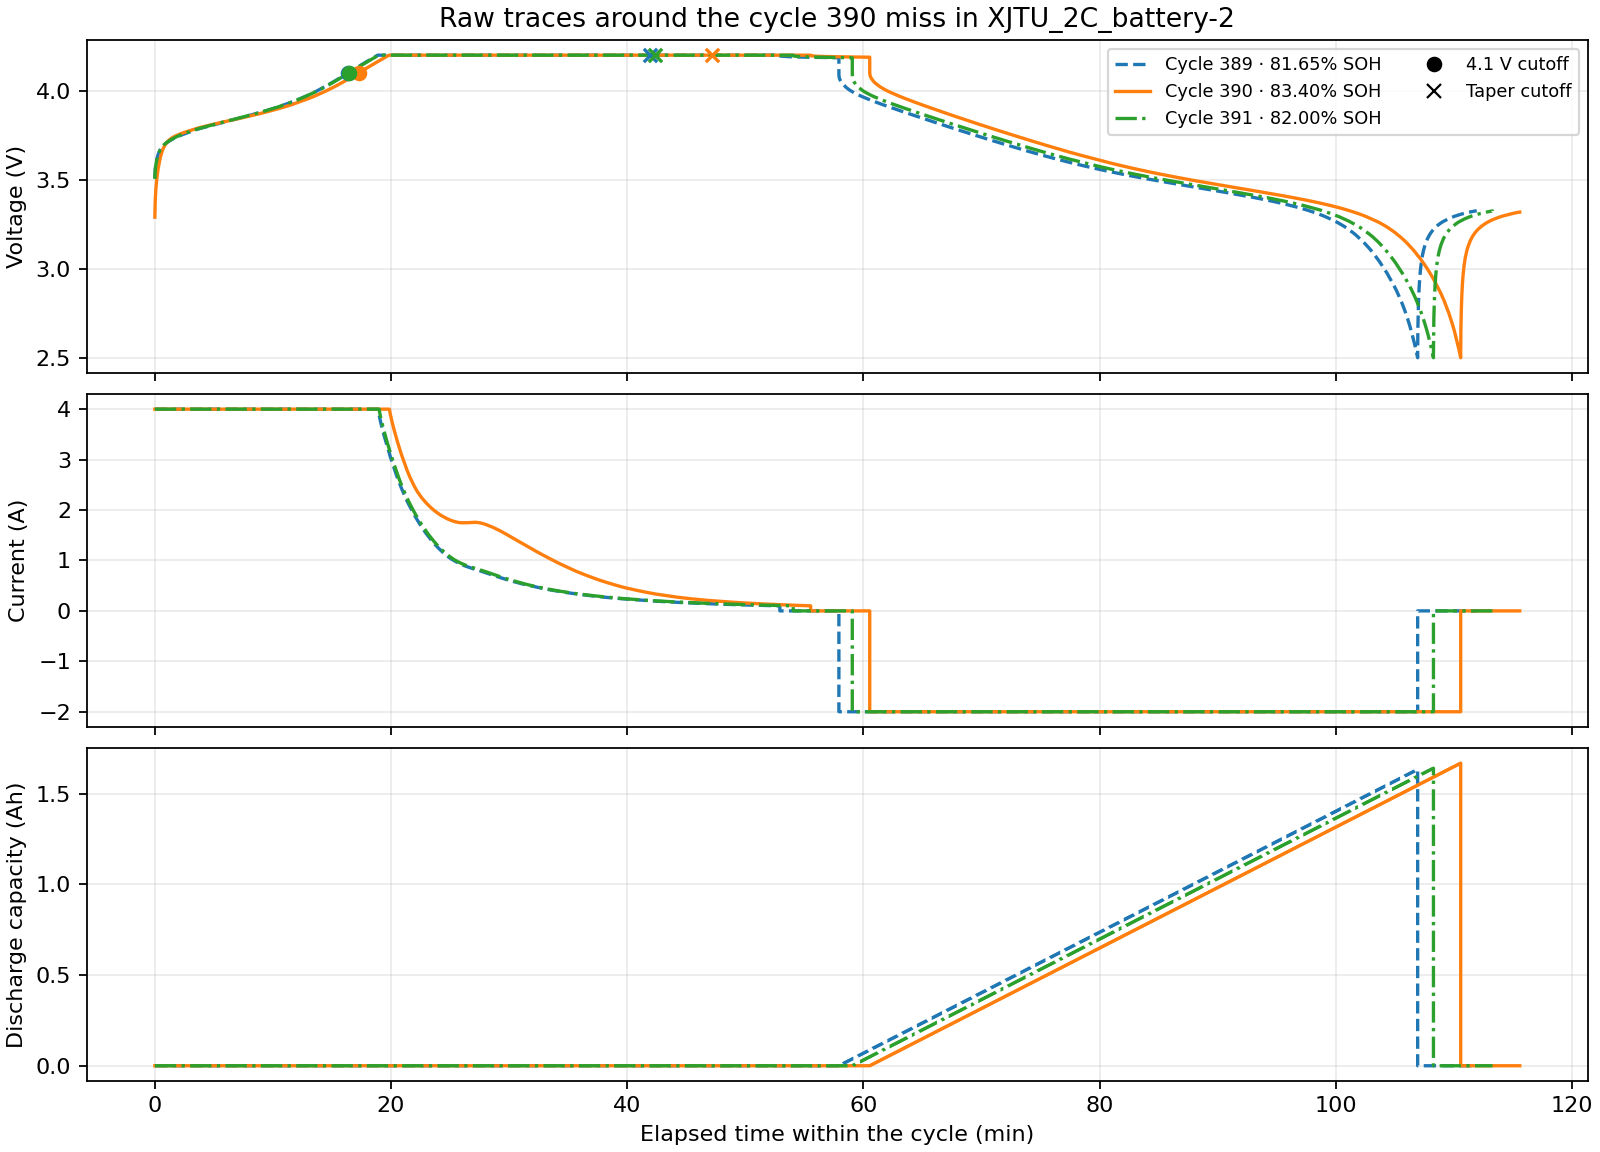

Download lifeguard_soh_validation_results.zip from the notebook output.


In [46]:
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
destination = OUTPUT_ROOT / "lifeguard_soh_validation_results.zip"
config = {
    "dataset": "BatteryLife v12",
    "dataset_doi": "10.5281/zenodo.21149533",
    "seed": SEED,
    "cells": list(FIXED_CELLS),
    "total_cycles": len(quality),
    "early_cycles": int((quality.early_status == "ok").sum()),
    "late_cycles": int((quality.late_status == "ok").sum()),
    "matched_cycles": len(data),
    "near_eol_threshold_pct": NEAR_EOL_SOH,
    "cnn_status": "pending" if RUN_CNN else "disabled",
    "packages": {pkg: version(pkg) for pkg in ("numpy", "pandas", "scikit-learn", "matplotlib")},
}

with TemporaryDirectory(prefix="lifeguard_validation_", dir=OUTPUT_ROOT) as temporary:
    work = Path(temporary)
    output = work / "results"
    output.mkdir()
    splits, split_table = build_splits(data)
    split_table.to_csv(output / "cell_splits.csv", index=False)
    quality.to_csv(output / "cycle_quality.csv", index=False)
    data.to_csv(output / "cycle_features.csv", index=False)

    with threadpool_limits(limits=4):
        predictions, tuning = run_cpu_validation(data, splits)
    check_predictions(data, predictions, splits)
    tuning.to_csv(output / "boosting_parameters.csv", index=False)
    metrics = export_predictions(output, predictions)
    export_outlier(output, quality, data, predictions, outlier_traces)
    publish_results(work, output, destination, config, metrics, quality)
    print(f"CPU results saved to {destination}")

    if RUN_CNN:
        try:
            cnn, epochs, folds, device_info = run_single_gpu_cnn(data, charge_curves, splits)
            combined = pd.concat([predictions, cnn], ignore_index=True)
            check_predictions(data, combined, splits, include_cnn=True)
        except Exception as error:
            config["cnn_status"] = "failed"
            config["cnn_error"] = str(error)
            (output / "cnn_error.txt").write_text(traceback.format_exc(), encoding="utf-8")
            print(f"CNN failed. CPU results are available. {error}")
        else:
            config["cnn_status"] = "completed"
            config["cnn_device"] = device_info
            epochs.to_csv(output / "cnn_epochs.csv", index=False)
            folds.to_csv(output / "cnn_folds.csv", index=False)
            metrics = export_predictions(output, combined)
        publish_results(work, output, destination, config, metrics, quality)

    display(Markdown((output / "summary.md").read_text(encoding="utf-8")))
    display(Image(filename=str(output / "cycle_390_raw_trace.png")))

print(f"Download {destination.name} from the notebook output.")